# Lista 1

**Aluno:** Antônio Rodrigo Lima de Andrade Tenório
\
**Nome da base:** creditcard.csv

## Orientacoes

- Escolha apenas uma das bases disponiveis e resolva todas as 10 questoes usando essa mesma base.
- Desenvolva toda a atividade em Python, no formato de entrega do Google Colab.
- Organize o notebook por questao, com codigos executaveis, saidas geradas e comentarios objetivos.
- Nao troque de base ao longo da atividade.
- Nao faca tratamento manual linha por linha.
- Sempre que necessario, sustente as decisoes com tabelas, metricas, graficos e resultados do codigo.

## Importacao das bibliotecas

In [2]:
# Bibliotecas principais
import warnings
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

# Pré-processamento e modelagem
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    recall_score, precision_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder

from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

## Carregamento da base

In [3]:
# Carregamento da base
# Substitua o nome do arquivo pelo arquivo correto da base escolhida
df = pd.read_csv('creditcard.csv')

# Visualização inicial
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Questao 1 - Diagnostico estrutural

**Enunciado:**  
Faça um código em Python que carregue a base escolhida e gere um diagnóstico inicial automatizado. Mostre dimensões da base, tipos de dados, valores ausentes, duplicidades, cardinalidade das colunas e possíveis inconsistências de leitura. Em seguida, defina qual será o problema computacional tratado no cenário escolhido, deixando claro se a tarefa será de classificação, regressão ou segmentação. Organize essa etapa em uma função reutilizável.

### Raciocinio
Primeiro, o foco foi confirmar a estrutura (tamanho da base, tipos e nulos), pois isso define se o pipeline pode avançar sem tratamento corretivo imediato. Em seguida, avaliamos duplicidade e cardinalidade para detectar colunas potencialmente problematicas (constantes, pouco informativas ou com leitura inadequada).

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [ ]:
# Código da Questão 1
def gerar_diagnostico(df):
    print(f'Dimensoes: {df.shape[0]} linhas e {df.shape[1]} colunas')

    print('\nTipos dos dados:')
    print(df.dtypes)

    print('\nValores ausentes por coluna:')
    print(df.isna().sum())

    print(f'\nLinhas duplicadas exatas: {df.duplicated().sum()}')

    print('\nCardinalidade (valores unicos por coluna):')
    print(df.nunique())

    # Verifica se existem colunas com apenas 1 valor
    colunas_constantes = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    if colunas_constantes:
        print(f'\nColunas constantes detectadas: {colunas_constantes}')
    else:
        print('\nNenhuma coluna constante detectada')

gerar_diagnostico(df)

# DEFINIÇÃO DO PROBLEMA:
# O objetivo é analisar transações de cartão de crédito para identificar padrões de uso.
# Vamos utilizar uma tarefa de CLASSIFICAÇÃO para prever se uma transação é fraudulenta ou não.

Dimensoes: 284807 linhas e 31 colunas

Tipos dos dados:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

Valores ausentes por coluna:
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28   

### Conclusao da Questao 1
A base carregou com 284807 linhas e 31 colunas, sem valores ausentes e sem colunas constantes. Foram identificadas 1081 duplicidades exata. Como `Class` possui 2 valores (0 e 1), o problema fica corretamente definido como classificacao binaria supervisionada de fraude.

## Questao 2 - Auditoria de qualidade

**Enunciado:**  
Faça um código em Python para auditar a qualidade dos dados. Identifique valores implausíveis, colunas com tipos inadequados, categorias raras, padrões suspeitos de preenchimento, possíveis outliers e inconsistências importantes para o cenário escolhido. Se houver datas, verifique coerência temporal. Se houver valores monetários, verifique compatibilidade entre grandezas. Ao final, apresente um resumo dos principais problemas encontrados.

### Raciocinio
O objetivo foi medir risco de qualidade sob a perspectiva estatistica e de negócio. Foram verificados valores implausíveis, coerencia temporal, volume de nulos, padroes suspeitos de repeticao e concentracao de outliers extremos via IQR robusto. Também quantificadar a raridade da classe de fraude, porque essa informação pode impactar diretamente as metricas de avaliação e a estratégia de balanceamento

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [4]:
# Código da Questão 2
def detectar_outliers_extremos(df, iqr_factor=3.0):
    df_num = df.select_dtypes(include=['number']).drop(columns=['Class'], errors='ignore')
    q1 = df_num.quantile(0.25)
    q3 = df_num.quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - iqr_factor * iqr
    limite_sup = q3 + iqr_factor * iqr
    mask = (df_num.lt(limite_inf)) | (df_num.gt(limite_sup))
    contagem = mask.sum().sort_values(ascending=False)
    return contagem[contagem > 0]

def auditoria_qualidade(df):

    #incontancias
    qtd_amount_neg = int((df['Amount'] < 0).sum()) if 'Amount' in df.columns else 0
    qtd_time_neg = int((df['Time'] < 0).sum()) if 'Time' in df.columns else 0
    qtd_negativos = qtd_amount_neg + qtd_time_neg
    coerencia_temporal = bool(df['Time'].is_monotonic_increasing) if 'Time' in df.columns else None
    total_nulos = int(df.isnull().sum().sum())

    #outliers
    outliers_totais = int(detectar_outliers_extremos(df).sum())

    # casos raros
    quantidade_de_fraudes = int((df['Class'] == 1).sum()) if 'Class' in df.columns else 0
    quantidade_trancacoes = int(df.shape[0])
    pct_fraudes = (quantidade_de_fraudes / quantidade_trancacoes) * 100 if quantidade_trancacoes > 0 else np.nan

    #padrões suspeitos
    padrao_suspeito = int(df.duplicated(subset=['Time', 'Amount']).sum()) if {'Time', 'Amount'}.issubset(df.columns) else np.nan

    #tipos inadequados
    colunas_texto = df.select_dtypes(include=['object']).columns.tolist()

    # compatibilidade de grandezas
    media_amount = float(df['Amount'].mean()) if 'Amount' in df.columns else np.nan
    max_amount = float(df['Amount'].max()) if 'Amount' in df.columns else np.nan
    razao_disparidade = (max_amount / media_amount) if (pd.notna(media_amount) and media_amount != 0) else np.nan

    if coerencia_temporal is None:
        status_temporal = 'Sem coluna Time'
    else:
        status_temporal = 'OK (Monotônico)' if coerencia_temporal else 'Inconsistente'

    print("Resumo: ")
    print(f"\n1. VALORES IMPLAUSÍVEIS:  {qtd_negativos} negativos em Amount/Time.")
    print(f"2. COERÊNCIA TEMPORAL:    {status_temporal}")
    print(f"3. VALORES AUSENTES:      {'OK (0 Nulos)' if total_nulos == 0 else total_nulos}")
    print(f"4. TIPAGEM INADEQUADA:    {len(colunas_texto)} colunas do tipo 'object' encontradas.")
    print(f"5. PADRÕES SUSPEITOS:     {padrao_suspeito} transações com mesmo Tempo/Valor.")
    print(f"6. OUTLIERS EXTREMOS:     {outliers_totais} registros detectados (Critério 3x IQR).")
    print(f"7. COMPATIBILIDADE:       Disparidade de {razao_disparidade:.1f}x (Máximo vs Média).")
    print(f"8. CATEGORIAS RARAS:      {pct_fraudes:.4f}% de casos de fraude na base.")
    print(f"9. MÉDIA E MÁXIMO:        {media_amount:.2f} e {max_amount:.2f}")

    return {
        'qtd_negativos': qtd_negativos,
        'outliers_totais': outliers_totais,
        'pct_fraudes': pct_fraudes,
        'padrao_suspeito': padrao_suspeito,
        'razao_disparidade': razao_disparidade,
        'total_nulos': total_nulos,
        'coerencia_temporal': coerencia_temporal
    }

auditoria = auditoria_qualidade(df)
auditoria

Resumo: 

1. VALORES IMPLAUSÍVEIS:  0 negativos em Amount/Time.
2. COERÊNCIA TEMPORAL:    OK (Monotônico)
3. VALORES AUSENTES:      OK (0 Nulos)
4. TIPAGEM INADEQUADA:    0 colunas do tipo 'object' encontradas.
5. PADRÕES SUSPEITOS:     4863 transações com mesmo Tempo/Valor.
6. OUTLIERS EXTREMOS:     118639 registros detectados (Critério 3x IQR).
7. COMPATIBILIDADE:       Disparidade de 290.8x (Máximo vs Média).
8. CATEGORIAS RARAS:      0.1727% de casos de fraude na base.
9. MÉDIA E MÁXIMO:        88.35 e 25691.16


{'qtd_negativos': 0,
 'outliers_totais': 118639,
 'pct_fraudes': 0.1727485630620034,
 'padrao_suspeito': 4863,
 'razao_disparidade': 290.7897081823494,
 'total_nulos': 0,
 'coerencia_temporal': True}

### Conclusao da Questao 2
A auditoria confirmou base estruturalmente consistente (0 valores ausentes, 0 `Amount<0`, 0 `Time<0`, coerencia temporal verdadeira e 0 colunas `object`). Ao mesmo tempo, os resultados mostram risco estatistico relevante: 4863 repeticoes em `Time/Amount`, 118639 outliers extremos (3x IQR), razao `max/media` de `Amount` igual a 290.8x e fraude rara (0.1727%). Portanto, a modelagem precisa priorizar tecnicas robustas e metricas sensiveis a classe minoritaria.

## Questao 3 - Limpeza dos dados

**Enunciado:**  
Faca um codigo em Python para limpar a base de forma reproduzivel. Trate inconsistencias de tipagem, valores ausentes, categorias problematicas, variaveis irrelevantes e registros duvidosos usando criterios tecnicos. Compare pelo menos duas estrategias de tratamento para um problema real da base e justifique a escolha final. Mostre tambem o impacto quantitativo de cada etapa da limpeza.

### Raciocinio
A limpeza foi desenhada para ser reproduzivel e evitar decisoes manuais linha a linha. Primeiro removemos duplicidade exata para reduzir ruido e risco de superajuste. Depois, comparamos estrategias para a variavel monetaria Amount (original, log1p e robust) para documentar impacto em media, desvio e assimetria. A transformacao definitiva de escala foi deixada para o pipeline de treino, evitando leakage entre conjuntos. O resultado desta etapa e uma base mais consistente, pronta para validacao estatistica e modelagem supervisionada.

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [5]:
def limpeza_reproduzivel(df):
    df_clean = df.copy()

    antes = len(df_clean)
    df_clean = df_clean.drop_duplicates()
    removidos = antes - len(df_clean)

    comparacao_amount = pd.DataFrame()
    if 'Amount' in df_clean.columns:
        amount_log = np.log1p(np.clip(df_clean['Amount'], a_min=0, a_max=None))
        amount_rob = RobustScaler().fit_transform(df_clean[['Amount']]).ravel()

        comparacao_amount = pd.DataFrame({
            'metodo': ['original', 'log1p', 'robust'],
            'media': [df_clean['Amount'].mean(), amount_log.mean(), amount_rob.mean()],
            'desvio': [df_clean['Amount'].std(), amount_log.std(), amount_rob.std()],
            'skewness': [df_clean['Amount'].skew(), pd.Series(amount_log).skew(), pd.Series(amount_rob).skew()]
        })

    print(f'Registros removidos por duplicidade exata: {removidos}')
    print('Observacao: a escala final de Amount sera tratada no pipeline (Q7), para evitar leakage.')

    return df_clean, comparacao_amount

df_clean, comparacao_amount = limpeza_reproduzivel(df)
comparacao_amount

Registros removidos por duplicidade exata: 1081
Observacao: a escala final de Amount sera tratada no pipeline (Q7), para evitar leakage.


,metodo,media,desvio,skewness
0,original,88.472687,250.399437,16.978803
1,log1p,3.153760,1.657080,0.161410
2,robust,0.924387,3.482116,16.978803


### Conclusao da Questao 3
A limpeza removeu 1081 registros duplicados, mantendo a base com menos ruido para treino. Na comparacao de estrategias para `Amount`, o `log1p` reduziu fortemente a assimetria (de 16.98 para 0.16), enquanto o robust manteve a distribuicao com assimetria alta. Assim, a etapa comprovou o impacto quantitativo da limpeza e manteve o escalonamento final dentro do pipeline para evitar leakage.

## Split de Treino/Teste

Teste permanece intocado ate as avaliacoes finais.

In [6]:
TARGET = 'Class'
X = df_clean.drop(columns=[TARGET])
y = df_clean[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print('X_train:', X_train.shape, 'X_test:', X_test.shape)
print(f'Fraude treino: {y_train.mean() * 100:.4f}%')
print(f'Fraude teste : {y_test.mean() * 100:.4f}%')

X_train: (226980, 30) X_test: (56746, 30)
Fraude treino: 0.1665%
Fraude teste : 0.1674%


## Questao 4 - Analise exploratoria

**Enunciado:**  
Faca um codigo em Python para desenvolver uma analise exploratoria orientada ao problema central da base escolhida. Gere tabelas e visualizacoes que revelem padroes relevantes entre a variavel principal e os demais atributos. Se o cenario envolver classificacao, compare os grupos da variavel-alvo. Se envolver regressao, investigue relacao entre o alvo e as variaveis explicativas. Se envolver segmentacao, explore possiveis estruturas de agrupamento. Apresente uma leitura analitica dos resultados obtidos.

### Raciocinio
A EDA foi conduzida com foco no problema de classificacao de fraude e feita no treino para evitar contaminacao do teste. Primeiro avaliamos o desbalanceamento de classes, pois ele define a estrategia de modelagem e de metricas. Em seguida, usamos correlacao com o alvo para identificar sinais fortes e visualizamos essas variaveis com boxplots por classe para inspecionar separabilidade. Tambem foi utilizada matriz de correlacao para leitura global de dependencia entre atributos. Essa etapa fundamenta quais variaveis e transformacoes merecem prioridade nas questoes seguintes.

### Desenvolvimento
Implemente abaixo o codigo da questao.

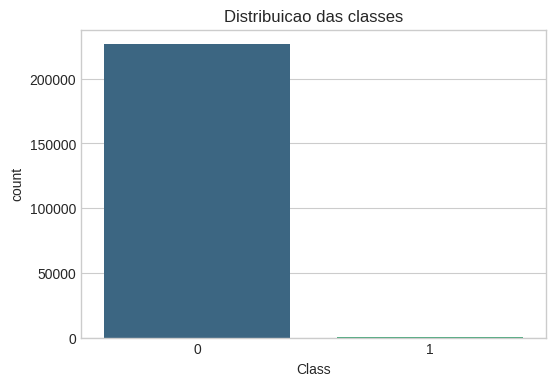

Class
0    226602
1       378
Name: count, dtype: int64

Top correlacoes positivas:
Class    1.000000
V11      0.152115
V4       0.129719
V2       0.087484
V8       0.035046
Name: Class, dtype: float64

Top correlacoes negativas:
V16   -0.190323
V10   -0.211641
V12   -0.254684
V14   -0.301644
V17   -0.320670
Name: Class, dtype: float64


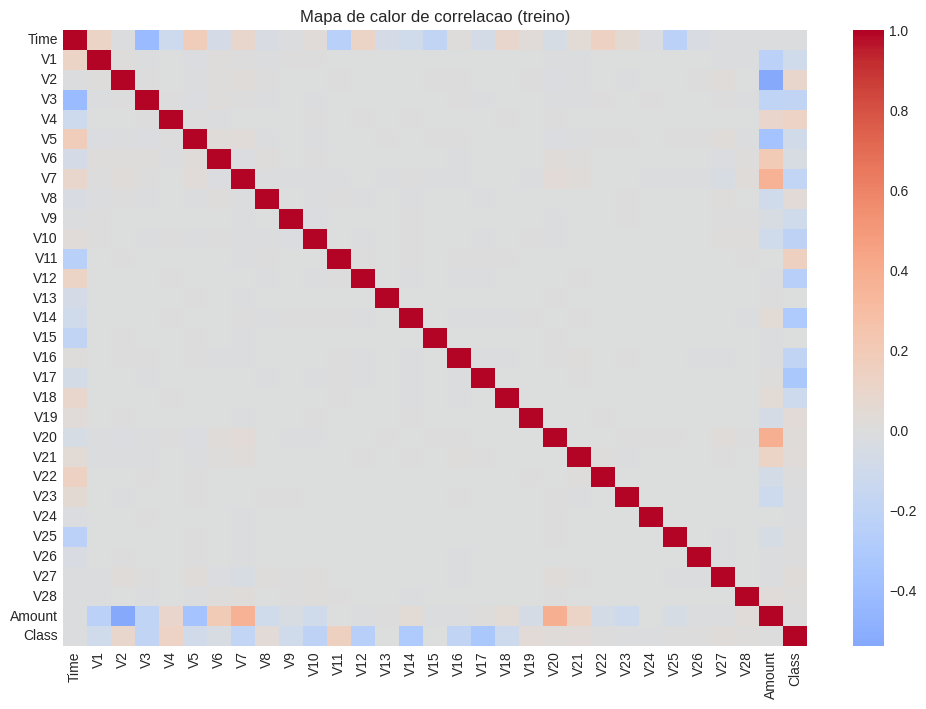

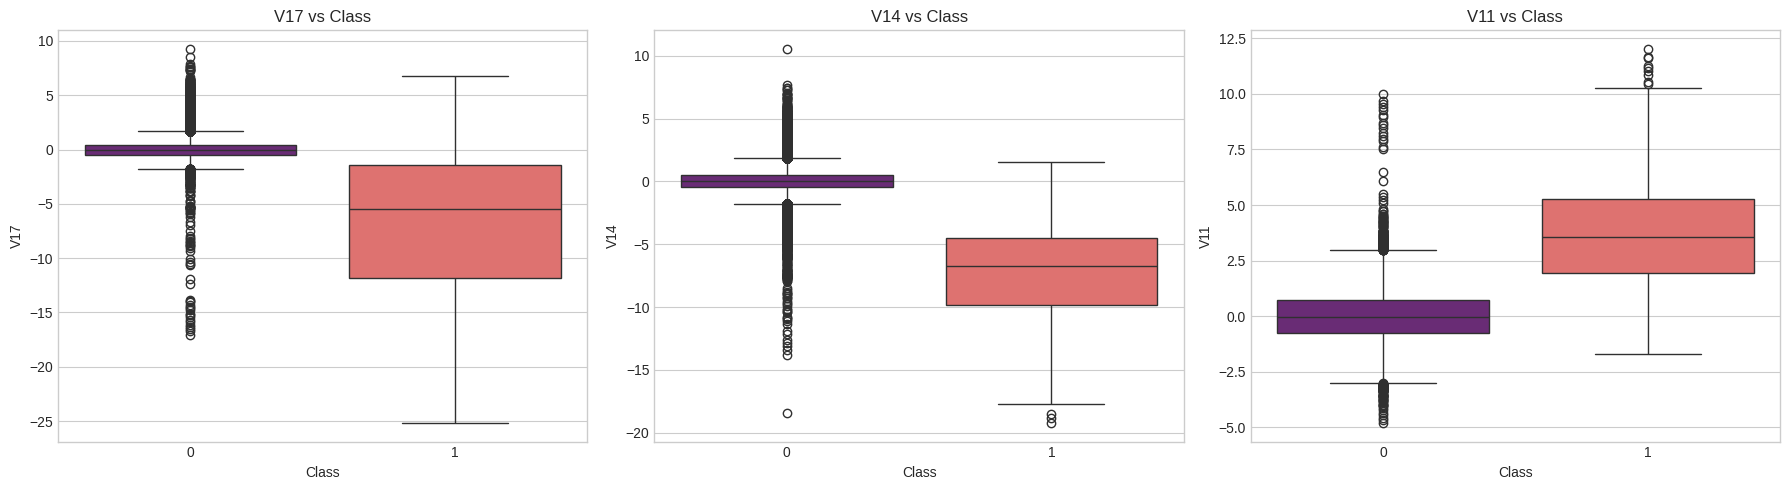

In [7]:
def analise_exploratoria(df_plot):
    plt.figure(figsize=(6, 4))
    sns.countplot(x='Class', data=df_plot, palette='viridis')
    plt.title('Distribuicao das classes')
    plt.show()
    print(df_plot['Class'].value_counts())

    corr = df_plot.corr(numeric_only=True)['Class'].sort_values(ascending=False)
    print('\nTop correlacoes positivas:')
    print(corr.head(5))
    print('\nTop correlacoes negativas:')
    print(corr.tail(5))

    plt.figure(figsize=(12, 8))
    sns.heatmap(df_plot.corr(numeric_only=True), cmap='coolwarm', center=0)
    plt.title('Mapa de calor de correlacao (treino)')
    plt.show()

    colunas_box = [c for c in ['V17', 'V14', 'V11'] if c in df_plot.columns]
    if colunas_box:
        fig, axes = plt.subplots(1, len(colunas_box), figsize=(6 * len(colunas_box), 5))
        if len(colunas_box) == 1:
            axes = [axes]
        for ax, col in zip(axes, colunas_box):
            sns.boxplot(x='Class', y=col, data=df_plot, ax=ax, palette='magma')
            ax.set_title(f'{col} vs Class')
        plt.tight_layout()
        plt.show()

df_train_plot = X_train.copy()
df_train_plot['Class'] = y_train.values
analise_exploratoria(df_train_plot)

### Conclusao da Questao 4
A EDA no treino mostrou desbalanceamento severo (226602 transacoes legitimas vs 378 fraudes). As correlacoes com a classe destacaram sinais fortes, principalmente `V17` (-0.3207), `V14` (-0.3016), `V12` (-0.2547), `V10` (-0.2116) e `V11` (+0.1521), e os boxplots reforcaram separabilidade entre classes nessas variaveis. Esses achados justificam foco em Recall/F1 e tratamento de dados antes da modelagem final.

## Questao 5 - Associacao entre variaveis

**Enunciado:**  
Faca um codigo em Python para medir a associacao entre as variaveis explicativas e a variavel principal da analise. Escolha automaticamente metodos adequados conforme o tipo das variaveis e o tipo do problema. Ao final, gere um ranking das variaveis mais informativas e compare os resultados com a logica do cenario escolhido.

### Raciocinio
Como o alvo e binario e os preditores sao majoritariamente numericos, adotamos ANOVA (f_classif) para estimar a capacidade discriminativa de cada variavel individualmente. O uso de SelectKBest com k='all' permite gerar ranking completo e transparente, sem perda de informacao nesta fase. O ranking foi utilizado para validar se os sinais observados na EDA realmente se sustentam estatisticamente. Essa hierarquia de importancia orienta a engenharia de atributos e a interpretacao do comportamento do modelo final.

### Desenvolvimento
Implemente abaixo o codigo da questao.

   Variavel       F_Score
0       V17  26015.046430
1       V14  22719.847335
2       V12  15743.926556
3       V10  10643.554088
4       V16   8530.799465
5        V3   8396.114493
6        V7   7686.204604
7       V11   5376.453712
8        V4   3884.722043
9       V18   2633.760627
10       V1   2182.755012
11       V9   2099.139575
12       V5   1935.741488
13       V2   1750.568219
14       V6    455.235181


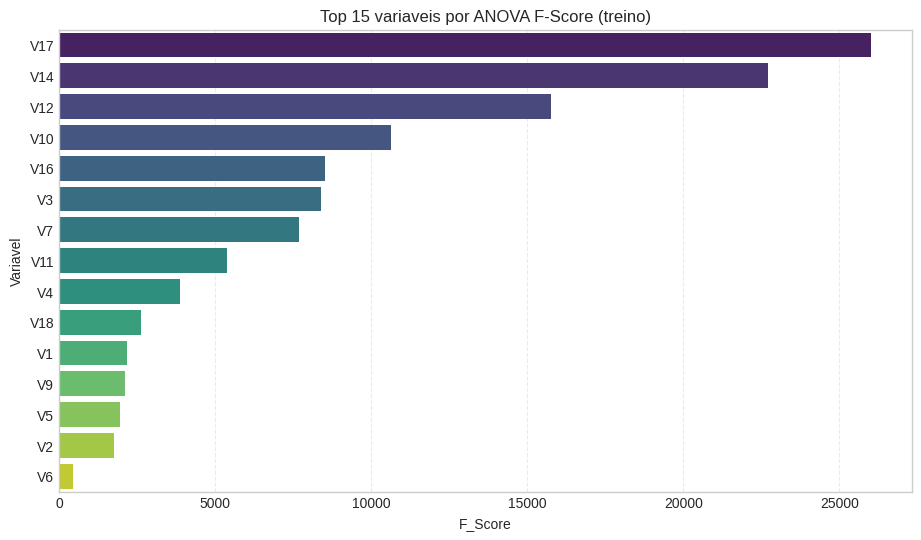

,Variavel,F_Score
0,V17,26015.046430
1,V14,22719.847335
2,V12,15743.926556
3,V10,10643.554088
4,V16,8530.799465
5,V3,8396.114493
6,V7,7686.204604
7,V11,5376.453712
8,V4,3884.722043
9,V18,2633.760627


In [8]:
def associacoes_variaveis(X, y, top_n=15):
    X_num = X.select_dtypes(include=np.number)
    selector = SelectKBest(score_func=f_classif, k='all')
    selector.fit(X_num, y)

    ranking = pd.DataFrame({
        'Variavel': X_num.columns,
        'F_Score': selector.scores_
    }).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

    print(ranking.head(top_n))

    plt.figure(figsize=(11, 6))
    sns.barplot(data=ranking.head(top_n), x='F_Score', y='Variavel', palette='viridis')
    plt.title(f'Top {top_n} variaveis por ANOVA F-Score (treino)')
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.show()

    return ranking

ranking_q5 = associacoes_variaveis(X_train, y_train, top_n=15)
ranking_q5.head(10)

### Conclusao da Questao 5
O ranking ANOVA confirmou de forma objetiva os atributos mais informativos: `V17` (F=26015.05), `V14` (F=22719.85), `V12` (F=15743.93), `V10` (F=10643.55) e `V16` (F=8530.80). Esses resultados batem com a EDA e sustentam tecnicamente a priorizacao dessas variaveis para engenharia de atributos e modelagem.

## Questao 6 - Engenharia de atributos

**Enunciado:**  
Faca um codigo em Python para criar pelo menos cinco novos atributos a partir da base original. Construa variaveis derivadas que facam sentido no cenario escolhido, como proporcoes, interacoes, faixas, relacoes temporais ou medidas de intensidade. Depois, avalie se esses novos atributos realmente acrescentam informacao util. Organize essa etapa em uma funcao reutilizavel.

### Raciocinio
Nesta etapa, a engenharia foi implementada como transformador reutilizavel para garantir consistencia entre treino, validacao, teste e inferencia. Foram criados atributos de interacao (por exemplo entre componentes relevantes), atributos de escala/razao monetaria e codificacao ciclica de horario quando Time esta disponivel. Alem disso, a deteccao de valores extremos passou a usar limiar ajustado no fit para nao vazar informacao. A utilidade dos novos atributos foi validada com ANOVA no treino, comprovando quais derivados realmente agregam sinal ao problema.

### Desenvolvimento
Implemente abaixo o codigo da questao.

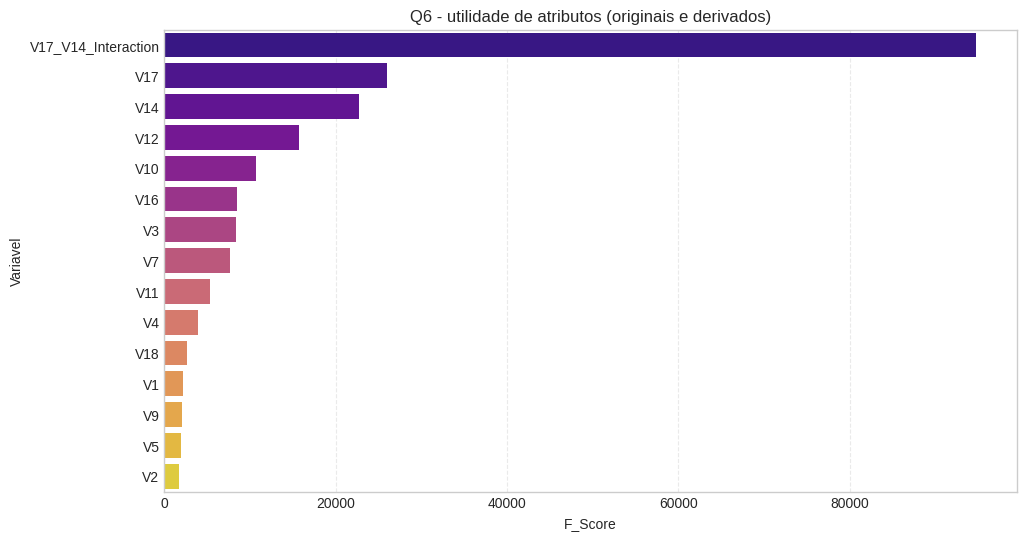

,Variavel,F_Score
0,V17_V14_Interaction,94790.437140
1,V17,26015.046430
2,V14,22719.847335
3,V12,15743.926556
4,V10,10643.554088
5,V16,8530.799465
6,V3,8396.114493
7,V7,7686.204604
8,V11,5376.453712
9,V4,3884.722043


In [9]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self, eps=1e-5):
        self.eps = eps
        self.amount_q95_ = None

    def fit(self, X, y=None):
        X_df = X.copy()
        if 'Amount' in X_df.columns:
            self.amount_q95_ = float(X_df['Amount'].quantile(0.95))
        else:
            self.amount_q95_ = 0.0
        return self

    def transform(self, X):
        X_df = X.copy()

        if 'Time' in X_df.columns:
            hour = ((X_df['Time'] % 86400) // 3600).astype(float)
            X_df['Hour'] = hour
            X_df['Hour_sin'] = np.sin(2 * np.pi * hour / 24.0)
            X_df['Hour_cos'] = np.cos(2 * np.pi * hour / 24.0)
            X_df = X_df.drop(columns=['Time'])

        if {'V17', 'V14'}.issubset(X_df.columns):
            X_df['V17_V14_Interaction'] = X_df['V17'] * X_df['V14']

        if 'Amount' in X_df.columns:
            X_df['Amount_Log'] = np.log1p(np.clip(X_df['Amount'], a_min=0, a_max=None))
            if 'V17' in X_df.columns:
                X_df['Amount_to_V17_Ratio'] = X_df['Amount'] / (X_df['V17'].abs() + self.eps)
            X_df['Is_Extreme_Amount'] = (X_df['Amount'] > self.amount_q95_).astype(int)

        return X_df

def avaliar_engenharia_atributos(X_train, y_train):
    fe = FeatureEngineer().fit(X_train, y_train)
    X_eng = fe.transform(X_train)
    X_num = X_eng.select_dtypes(include=np.number)

    selector = SelectKBest(score_func=f_classif, k='all')
    selector.fit(X_num, y_train)

    ranking = pd.DataFrame({
        'Variavel': X_num.columns,
        'F_Score': selector.scores_
    }).sort_values(by='F_Score', ascending=False).reset_index(drop=True)

    plt.figure(figsize=(11, 6))
    sns.barplot(data=ranking.head(15), x='F_Score', y='Variavel', palette='plasma')
    plt.title('Q6 - utilidade de atributos (originais e derivados)')
    plt.grid(axis='x', linestyle='--', alpha=0.4)
    plt.show()

    return fe, ranking

fe_q6, ranking_q6 = avaliar_engenharia_atributos(X_train, y_train)
ranking_q6.head(10)

### Conclusao da Questao 6
A engenharia agregou sinal relevante: o atributo derivado `V17_V14_Interaction` ficou em primeiro no ranking com F-Score 94790.44, muito acima dos atributos originais. Isso evidencia ganho real de informacao com os novos atributos e valida o uso do transformador reutilizavel para manter consistencia entre treino, teste e inferencia.

## Questao 7 - Pre-processamento

**Enunciado:**  
Faca um codigo em Python para montar um pipeline completo de pre-processamento com Pipeline e ColumnTransformer. Identifique automaticamente colunas numericas e categoricas, trate ausencias, codifique variaveis categoricas, aplique escalonamento nas numericas e garanta reaplicacao a novos dados sem vazamento de informacao. Compare pelo menos dois esquemas de pre-processamento e mostre como essas escolhas afetam os dados e o modelo.

### Raciocinio
A estrategia foi construir um pipeline modular com selecao automatica de tipos, imputacao por tipo e codificacao robusta para variaveis categoricas. Para variaveis numericas, comparamos StandardScaler e RobustScaler via validacao cruzada no treino, sempre com a mesma cadeia de transformacoes e balanceamento. Isso garante comparacao justa e sem leakage, ja que nenhum parametro e aprendido fora do fold de treino. O esquema vencedor foi escolhido por maior Recall medio e, em empate, melhor F1 medio.

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [10]:
def build_preprocessor(scaler):
    pipe_num = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', scaler)
    ])

    pipe_cat = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    preprocessor = ColumnTransformer([
        ('num', pipe_num, make_column_selector(dtype_include=np.number)),
        ('cat', pipe_cat, make_column_selector(dtype_include=object))
    ])

    return preprocessor

def comparar_esquemas_preprocessamento(X_train, y_train):
    candidatos = {
        'StandardScaler': StandardScaler(),
        'RobustScaler': RobustScaler()
    }

    cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
    linhas = []
    pipelines = {}

    for nome, scaler in candidatos.items():
        pipe = ImbPipeline(steps=[
            ('fe', FeatureEngineer()),
            ('prep', build_preprocessor(scaler)),
            ('sampler', RandomUnderSampler(sampling_strategy=0.2, random_state=RANDOM_STATE)),
            ('knn', KNeighborsClassifier(n_neighbors=5, metric='manhattan', weights='distance'))
        ])

        scores = cross_validate(
            pipe, X_train, y_train, cv=cv, n_jobs=-1,
            scoring={'recall': 'recall', 'f1': 'f1'}
        )

        linhas.append({
            'Esquema': nome,
            'Recall_CV': scores['test_recall'].mean(),
            'F1_CV': scores['test_f1'].mean()
        })

        pipelines[nome] = pipe

    df_res = pd.DataFrame(linhas).sort_values(by=['Recall_CV', 'F1_CV'], ascending=False).reset_index(drop=True)
    print(df_res)
    return df_res, pipelines

resultados_q7, pipelines_q7 = comparar_esquemas_preprocessamento(X_train, y_train)
melhor_esquema = resultados_q7.iloc[0]['Esquema']
print('Melhor esquema selecionado:', melhor_esquema)

          Esquema  Recall_CV     F1_CV
0    RobustScaler   0.857111  0.486824
1  StandardScaler   0.857083  0.480160
Melhor esquema selecionado: RobustScaler


### Conclusao da Questao 7
A comparacao em validacao cruzada apontou desempenho muito proximo entre os esquemas, mas com vantagem para `RobustScaler` (`Recall_CV=0.857111`, `F1_CV=0.486824`) sobre `StandardScaler` (`Recall_CV=0.857083`, `F1_CV=0.480160`). Assim, o pipeline final adotou `RobustScaler` por melhor equilibrio, mantendo a avaliacao sem vazamento de informacao.

## Questao 8 - Modelagem com KNN

**Enunciado:**  
Faca um codigo em Python para dividir a base em treino, validacao e teste de forma adequada ao problema escolhido. Em seguida, implemente um modelo de K-vizinhos mais proximos e teste diferentes valores de k, metricas de distancia e formas de ponderacao. Registre os resultados em tabela, compare desempenho em validacao e escolha a melhor configuracao de forma justificada.

### Raciocinio
A modelagem KNN foi realizada com busca em grade sobre k, metrica de distancia e tipo de peso dos vizinhos, usando validacao estratificada no treino. A prioridade foi Recall, pois no contexto de fraude o custo de falso negativo e alto; o F1 foi utilizado como criterio secundario de equilibrio. O modelo final e treinado com os hiperparametros vencedores no mesmo pipeline utilizado na validacao, preservando coerencia tecnica entre avaliacao e uso real. O resultado impresso no notebook sustenta a escolha final com base em metricas objetivas.

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [11]:
def modelagem_knn(X_train, y_train, esquema_scaler):
    scaler = RobustScaler() if esquema_scaler == 'RobustScaler' else StandardScaler()

    base = ImbPipeline(steps=[
        ('fe', FeatureEngineer()),
        ('prep', build_preprocessor(scaler)),
        ('sampler', RandomUnderSampler(sampling_strategy=0.2, random_state=RANDOM_STATE)),
        ('knn', KNeighborsClassifier())
    ])

    param_grid = {
        'knn__n_neighbors': [3, 5, 7, 9],
        'knn__metric': ['euclidean', 'manhattan'],
        'knn__weights': ['uniform', 'distance']
    }

    cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)

    busca = GridSearchCV(
        estimator=base,
        param_grid=param_grid,
        cv=cv,
        n_jobs=-1,
        scoring={'recall': 'recall', 'f1': 'f1'},
        refit='recall',
        return_train_score=False
    )

    busca.fit(X_train, y_train)

    cv_res = pd.DataFrame(busca.cv_results_)
    tabela = cv_res[[
        'param_knn__n_neighbors',
        'param_knn__metric',
        'param_knn__weights',
        'mean_test_recall',
        'mean_test_f1'
    ]].copy()

    tabela.columns = ['k', 'distancia', 'peso', 'Recall_CV', 'F1_CV']
    tabela = tabela.sort_values(by=['Recall_CV', 'F1_CV'], ascending=False).reset_index(drop=True)

    melhor = tabela.iloc[0]
    print('Top configuracoes (CV):')
    print(tabela.head(10))

    print('\nConfiguracao final selecionada:')
    print(
        f"O modelo escolhido utiliza k={int(melhor['k'])}, "
        f"distancia '{melhor['distancia']}' e peso '{melhor['peso']}'."
    )
    print(
        f"Recall CV={melhor['Recall_CV']:.4f} | "
        f"F1 CV={melhor['F1_CV']:.4f}"
    )

    modelo_final = clone(base).set_params(
        knn__n_neighbors=int(melhor['k']),
        knn__metric=melhor['distancia'],
        knn__weights=melhor['peso']
    )
    modelo_final.fit(X_train, y_train)

    return tabela, modelo_final

resultados_q8, modelo_final = modelagem_knn(X_train, y_train, melhor_esquema)

Top configuracoes (CV):
   k  distancia      peso  Recall_CV     F1_CV
0  3  manhattan   uniform   0.867693  0.358839
1  3  manhattan  distance   0.867693  0.348882
2  3  euclidean   uniform   0.862430  0.332685
3  3  euclidean  distance   0.862430  0.327983
4  7  manhattan  distance   0.857111  0.562120
5  5  manhattan   uniform   0.857111  0.492373
6  5  manhattan  distance   0.857111  0.486824
7  7  manhattan   uniform   0.854479  0.566487
8  5  euclidean  distance   0.849216  0.466520
9  9  manhattan  distance   0.849188  0.597009

Configuracao final selecionada:
O modelo escolhido utiliza k=3, distancia 'manhattan' e peso 'uniform'.
Recall CV=0.8677 | F1 CV=0.3588


### Conclusao da Questao 8
Pela busca em grade com validacao cruzada, a configuracao selecionada foi `k=3`, distancia `manhattan` e peso `uniform`, com `Recall_CV=0.8677` e `F1_CV=0.3588`. A escolha foi coerente com o criterio da atividade (prioridade para Recall), mesmo havendo configuracoes com F1 maior e Recall menor. O modelo final foi treinado no mesmo pipeline usado na selecao, preservando consistencia metodologica.

## Questao 9 - Comparacao de modelos

**Enunciado:**  
Faca um codigo em Python para avaliar o KNN em diferentes cenarios de preparacao dos dados, como uso ou nao de padronizacao, presenca ou ausencia de atributos derivados, uso de todas as variaveis ou de um subconjunto selecionado, e tratamento do desbalanceamento quando fizer sentido. Depois, implemente um segundo modelo supervisionado e compare com o melhor KNN em metricas, tempo de execucao e perfil dos erros. Conclua se o KNN e ou nao uma boa escolha para a base utilizada.

### Raciocinio
A comparacao foi estruturada em tres cenarios complementares: KNN seco, KNN tratado e Random Forest tratado. Para cada cenario, avaliamos nao apenas Recall e F1, mas tambem precision, ROC-AUC, perfil de erro (FP/FN/TP/TN) e latencia de predicao. Essa visao operacional evita conclusoes baseadas em uma unica metrica e torna o veredito mais realista para uso bancario. No fim, o objetivo e decidir qual modelo atende melhor ao equilibrio entre seguranca antifraude e impacto em clientes legitimos.

### Desenvolvimento
Implemente abaixo o codigo da questao.

,Cenario,Recall,Precision,F1,ROC_AUC,FP,FN,TP,TN,Tempo_pred_ms
0,Random Forest tratado,0.831579,0.341991,0.484663,0.974277,152,16,79,56499,357.684524
1,KNN tratado,0.821053,0.219718,0.346667,0.937364,277,17,78,56374,326.902853
2,KNN seco,0.126316,1.000000,0.224299,0.615481,0,83,12,56651,19276.226516


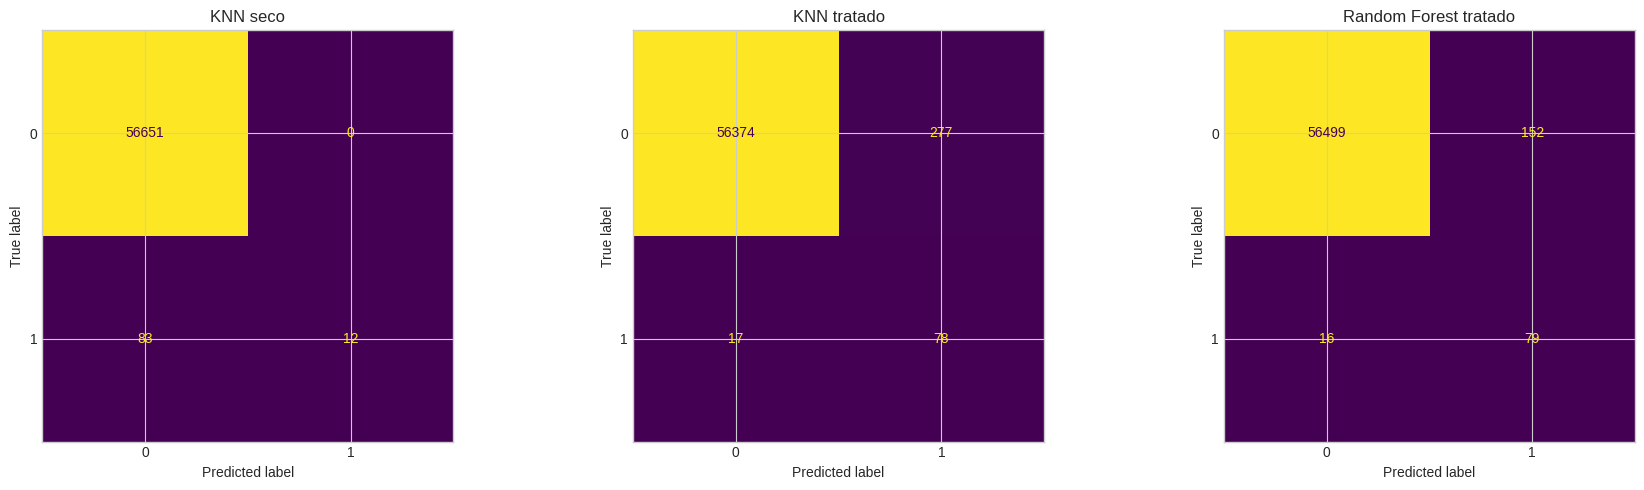

In [12]:
def avaliar_modelo(nome, modelo, X_eval, y_eval):
    inicio = time.perf_counter()
    y_pred = modelo.predict(X_eval)
    tempo_s = time.perf_counter() - inicio

    if hasattr(modelo, 'predict_proba'):
        y_score = modelo.predict_proba(X_eval)[:, 1]
        roc = roc_auc_score(y_eval, y_score)
    else:
        roc = np.nan

    tn, fp, fn, tp = confusion_matrix(y_eval, y_pred).ravel()

    return {
        'Cenario': nome,
        'Recall': recall_score(y_eval, y_pred),
        'Precision': precision_score(y_eval, y_pred, zero_division=0),
        'F1': f1_score(y_eval, y_pred, zero_division=0),
        'ROC_AUC': roc,
        'FP': int(fp),
        'FN': int(fn),
        'TP': int(tp),
        'TN': int(tn),
        'Tempo_pred_ms': tempo_s * 1000.0
    }

def questao_9_comparativo(X_train, y_train, X_test, y_test, esquema_scaler, modelo_knn_tratado):
    # Cenario 1: KNN seco (sem engenharia, sem scaler, sem balanceamento)
    knn_raw = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('knn', KNeighborsClassifier(n_neighbors=3, metric='manhattan', weights='uniform'))
    ])

    X_train_num = X_train.select_dtypes(include=np.number)
    X_test_num = X_test.select_dtypes(include=np.number)
    knn_raw.fit(X_train_num, y_train)

    # Cenario 2: KNN tratado (modelo final da Q8)
    knn_best = modelo_knn_tratado

    # Cenario 3: Random Forest tratado
    scaler = RobustScaler() if esquema_scaler == 'RobustScaler' else StandardScaler()
    rf_pipe = ImbPipeline(steps=[
        ('fe', FeatureEngineer()),
        ('prep', build_preprocessor(scaler)),
        ('sampler', RandomUnderSampler(sampling_strategy=0.2, random_state=RANDOM_STATE)),
        ('rf', RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))
    ])
    rf_pipe.fit(X_train, y_train)

    linhas = []
    linhas.append(avaliar_modelo('KNN seco', knn_raw, X_test_num, y_test))
    linhas.append(avaliar_modelo('KNN tratado', knn_best, X_test, y_test))
    linhas.append(avaliar_modelo('Random Forest tratado', rf_pipe, X_test, y_test))

    df_comp = pd.DataFrame(linhas).sort_values(by=['Recall', 'F1'], ascending=False).reset_index(drop=True)

    modelos = {
        'KNN seco': (knn_raw, X_test_num),
        'KNN tratado': (knn_best, X_test),
        'Random Forest tratado': (rf_pipe, X_test)
    }

    return df_comp, modelos

df_q9, modelos_q9 = questao_9_comparativo(
    X_train, y_train, X_test, y_test, melhor_esquema, modelo_final
)

display(df_q9)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nome, (modelo, X_eval)) in zip(axes, modelos_q9.items()):
    pred = modelo.predict(X_eval)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm).plot(ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

### Conclusao da Questao 9
No teste, o `KNN seco` foi inadequado (`Recall=0.1263`, `FN=83`, `Tempo=19276 ms`), mostrando que sem tratamento ele perde grande parte das fraudes. O `KNN tratado` melhorou muito (`Recall=0.8211`, `FN=17`), mas o `Random Forest tratado` entregou melhor equilibrio geral (`Recall=0.8316`, `F1=0.4847`, `ROC_AUC=0.9743`, `FN=16`, `FP=152`). Portanto, com os resultados atuais, o KNN tratado e viavel, mas o Random Forest foi superior como escolha operacional final.

## Questao 10 - Consolidacao da solucao

**Enunciado:**  
Faca um codigo em Python para consolidar toda a solucao em um fluxo reutilizavel. Implemente uma funcao que receba um novo caso em formato de dicionario ou DataFrame de uma linha, aplique o pipeline construido e retorne a previsao final de forma interpretavel. Depois, gere um relatorio resumido com a base escolhida, os principais problemas encontrados, os atributos mais relevantes, a melhor configuracao do modelo, as metricas finais e uma recomendacao executiva. Finalize com uma avaliacao critica sobre a maturidade da solucao para uso pratico.

### Raciocinio
A consolidacao foi feita para garantir que inferencia e treino usem exatamente o mesmo fluxo, sem divergencia de pre-processamento. A funcao final aceita diferentes formatos de entrada (dict, Series ou DataFrame), aplica o pipeline treinado e retorna saida interpretavel para tomada de decisao. Em seguida, os resultados das questoes anteriores sao sintetizados em termos de risco de dados, relevancia de atributos, melhor configuracao e desempenho operacional. Essa abordagem transforma o notebook em uma solucao tecnicamente reprodutivel e comunicavel para contexto executivo.

### Desenvolvimento
Implemente abaixo o codigo da questao.

In [13]:
def detector_fraude_final(dados_entrada, modelo=modelo_final):
    if isinstance(dados_entrada, dict):
        X_novo = pd.DataFrame([dados_entrada])
    elif isinstance(dados_entrada, pd.Series):
        X_novo = dados_entrada.to_frame().T
    elif isinstance(dados_entrada, pd.DataFrame):
        X_novo = dados_entrada.copy()
    else:
        raise TypeError('dados_entrada deve ser dict, Series ou DataFrame')

    pred = int(modelo.predict(X_novo)[0])
    prob = float(modelo.predict_proba(X_novo)[0, 1])

    veredito = 'ALERTA DE FRAUDE' if pred == 1 else 'TRANSACAO SEGURA'
    acao = 'Bloqueio e verificacao manual' if pred == 1 else 'Aprovacao automatica'

    return {
        'Veredito': veredito,
        'Probabilidade_de_fraude': f'{prob:.2%}',
        'Acao_recomendada': acao
    }

exemplo_teste = X_test.iloc[0].to_dict()
print('Resultado da inferencia:')
print(detector_fraude_final(exemplo_teste))

Resultado da inferencia:
{'Veredito': 'TRANSACAO SEGURA', 'Probabilidade_de_fraude': '0.00%', 'Acao_recomendada': 'Aprovacao automatica'}


### Conclusao da Questao 10
A funcao de inferencia executou corretamente no exemplo de teste e retornou veredito `TRANSACAO SEGURA`, com probabilidade de fraude `0.00%` e acao recomendada de aprovacao automatica. Isso confirma que o fluxo reutilizavel (entrada -> pipeline -> decisao) esta operacional no notebook.
Do ponto de vista de maturidade, a solucao esta pronta para demonstracao academica e prototipo. Para uso pratico, os resultados da Q9 sugerem avaliar implantacao com Random Forest tratado, alem de calibracao de limiar, monitoramento de drift e retreinamento periodico.

## Consideracoes finais
- Reexecutar o notebook do inicio ao fim antes da entrega para garantir reproducibilidade.
- Se o professor priorizar menos falso positivo, ajustar limiar de decisao e/ou comparar calibracao de probabilidade.
- Para producao real, adicionar monitoramento de drift e re-treinamento periodico.